In [22]:
# ignore this
.libPaths(c("/net/home/swolf/R/x86_64-pc-linux-gnu-library/4.4", .libPaths()))

# Global Spectrum of Plant Form and Function

## References

- Diaz et al., 2016, Global Spectrum of Plant Form and Function
- Weigelt et al. 2021, An integrated framework of plant form and function: the belowground perspective
- Wolf et al. 2022, Citizen science plant observations encode global trait patterns

## Exercise Outline

1. Correlate sPlotOpen data with trait grid cell averages

2. Calculate PCA with top traits from correlation analysis (come up with a good cut-off)
    - Plot variance explained
    - Plot biplots with loadings
    - Create global maps for the PCs that explain most variance
    - Try to interpret PCs in ecological terms
    - Describe what regions are not well covered and discuss how this may influence the PCA


3. Choose a biome and quantify and visualitze trait shifts from native -> all in a specific biome



## Data

- Grid-cell averages: ```/net/scratch/swolf/GBIF/gbif_CS_glonaf_wcvp_res3_try6_mean_imp.csv```
    - **h3_res3**: h3 hexagonal equal-area grid cells at reolution 3
    - **group**: only indigenous observations (native) and indigenous+non-indigenous observations
    - **count**: number of occurences per grid cell (sampling density)
    - - **37 above- and below-ground plant functional traits** (citizen-science species occurrence merged with TRY trait data), gap-filled

- sPlotOpen: ```~/iNaturalist/Data/sPlotOpen/cwm_loc.csv```
    - **PlotID**
    - **Latitude**
    - **Longitude**
    - **Community weighted means (CWM's)** for 18 above-ground traits **ln-transformed**!

- Trait names: ```~/Func_Neo_Phytes/Data/trait_info.csv```

- WWF biomes shapefile: ```~/iNaturalist/Data/WWF/wwf_terr_ecos.shp```

## Corrlate with sPlotOpen

1. Calculate grid-cell sPlotOpen averages

In [89]:
# read ~/iNaturalist/Data/sPlotOpen/cwm_loc.csv
splotopen <- read.csv("~/iNaturalist/Data/sPlotOpen/cwm_loc.csv")
head(splotopen)

,PlotObservationID,TraitCoverage_cover,Species_richness,TraitCoverage_pa,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,⋯,Height_shrubs_lowest,Height_herbs_average,Height_herbs_lowest,Height_herbs_highest,SoilClim_PC1,SoilClim_PC2,Resample_1,Resample_2,Resample_3,Resample_1_consensus
,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,16,0.27777778,3,0.3333333,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
2,17,0.03846154,2,0.5000000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
3,18,0.04761905,4,0.2500000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False
4,20,0.66666667,3,0.3333333,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,⋯,NA,NA,NA,NA,-3.66,0.546,False,True,False,False
5,22,0.53846154,7,0.5714286,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
6,23,0.95238095,13,0.8461538,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False


In [90]:
head(splotopen)
dim(splotopen)

,PlotObservationID,TraitCoverage_cover,Species_richness,TraitCoverage_pa,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,⋯,Height_shrubs_lowest,Height_herbs_average,Height_herbs_lowest,Height_herbs_highest,SoilClim_PC1,SoilClim_PC2,Resample_1,Resample_2,Resample_3,Resample_1_consensus
,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
1,16,0.27777778,3,0.3333333,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
2,17,0.03846154,2,0.5000000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
3,18,0.04761905,4,0.2500000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False
4,20,0.66666667,3,0.3333333,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,⋯,NA,NA,NA,NA,-3.66,0.546,False,True,False,False
5,22,0.53846154,7,0.5714286,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,⋯,NA,NA,NA,NA,-3.66,0.546,True,False,False,True
6,23,0.95238095,13,0.8461538,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,⋯,NA,NA,NA,NA,-3.66,0.546,False,False,True,False


[1] 95104    86

In [91]:
# add h3 hexagonal grid cell code at resolution 3

library(h3) 

splotopen$h3_res3 <- geo_to_h3(cbind(splotopen$Latitude, splotopen$Longitude), res = 3)
head(splotopen)

,PlotObservationID,TraitCoverage_cover,Species_richness,TraitCoverage_pa,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,⋯,Height_herbs_average,Height_herbs_lowest,Height_herbs_highest,SoilClim_PC1,SoilClim_PC2,Resample_1,Resample_2,Resample_3,Resample_1_consensus,h3_res3
,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>,<chr>
1,16,0.27777778,3,0.3333333,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
2,17,0.03846154,2,0.5000000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
3,18,0.04761905,4,0.2500000,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,⋯,NA,NA,NA,-3.66,0.546,False,False,True,False,830c0dfffffffff
4,20,0.66666667,3,0.3333333,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,⋯,NA,NA,NA,-3.66,0.546,False,True,False,False,830c0dfffffffff
5,22,0.53846154,7,0.5714286,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,⋯,NA,NA,NA,-3.66,0.546,True,False,False,True,830c0dfffffffff
6,23,0.95238095,13,0.8461538,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,⋯,NA,NA,NA,-3.66,0.546,False,False,True,False,830c0dfffffffff


In [92]:
#  columns splotopen
colnames(splotopen)
# filter for: 'Latitude','Longitude', 'Leaf.Area','SSD','SLA','Leaf.C','Leaf.N.per.mass','Leaf.P','Plant.Height','Seed.mass','Seed.length','LDMC','Leaf.N.per.area','Leaf.N.P.ratio','Leaf.delta15N','Seeds.per.rep..unit','Leaf.fresh.mass','Stem.conduit.density','Dispersal.unit.length','Conduit.element.length'
splotopen_sub <- splotopen[, c('Latitude','Longitude', 'Leaf.Area','SSD','SLA','Leaf.C','Leaf.N.per.mass','Leaf.P','Plant.Height','Seed.mass','Seed.length','LDMC','Leaf.N.per.area','Leaf.N.P.ratio','Leaf.delta15N','Seeds.per.rep..unit','Leaf.fresh.mass','Stem.conduit.density','Dispersal.unit.length','Conduit.element.length', 'h3_res3')]
head(splotopen_sub)



[1] "PlotObservationID"      "TraitCoverage_cover"    "Species_richness"      
 [4] "TraitCoverage_pa"       "Leaf.Area"              "SSD"                   
 [7] "SLA"                    "Leaf.C"                 "Leaf.N.per.mass"       
[10] "Leaf.P"                 "Plant.Height"           "Seed.mass"             
[13] "Seed.length"            "LDMC"                   "Leaf.N.per.area"       
[16] "Leaf.N.P.ratio"         "Leaf.delta15N"          "Seeds.per.rep..unit"   
[19] "Leaf.fresh.mass"        "Stem.conduit.density"   "Dispersal.unit.length" 
[22] "Conduit.element.length" "LeafArea_CWV"           "StemDens_CWV"          
[25] "SLA_CWV"                "LeafC_perdrymass_CWV"   "LeafN_CWV"             
[28] "LeafP_CWV"              "PlantHeight_CWV"        "SeedMass_CWV"          
[31] "Seed_length_CWV"        "LDMC_CWV"               "LeafNperArea_CWV"      
[34] "LeafNPratio_CWV"        "Leaf_delta_15N_CWV"     "Seed_num_rep_unit_CWV" 
[37] "Leaffreshmass_CWV"      "Stem_cond_dens_CWV"     "Disp_unit_leng_CWV"    
[40] "Wood_vessel_length_CWV" "GIVD_ID"                "Dataset"               
[43] "Continent"              "Country"                "Biome"                 
[46] "Date_of_recording"      "Latitude"               "Longitude"             
[49] "Location_uncertainty"   "Releve_area"            "Plant_recorded"        
[52] "Elevation"              "Aspect"                 "Slope"                 
[55] "is_forest"              "ESY"                    "Naturalness"           
[58] "Forest"                 "Shrubland"              "Grassland"             
[61] "Wetland"                "Sparse_vegetation"      "Cover_total"           
[64] "Cover_tree_layer"       "Cover_shrub_layer"      "Cover_herb_layer"      
[67] "Cover_moss_layer"       "Cover_lichen_layer"     "Cover_algae_layer"     
[70] "Cover_litter_layer"     "Cover_bare_rocks"       "Cover_cryptogams"      
[73] "Cover_bare_soil"        "Height_trees_highest"   "Height_trees_lowest"   
[76] "Height_shrubs_highest"  "Height_shrubs_lowest"   "Height_herbs_average"  
[79] "Height_herbs_lowest"    "Height_herbs_highest"   "SoilClim_PC1"          
[82] "SoilClim_PC2"           "Resample_1"             "Resample_2"            
[85] "Resample_3"             "Resample_1_consensus"   "h3_res3"

,Latitude,Longitude,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,Plant.Height,Seed.mass,⋯,LDMC,Leaf.N.per.area,Leaf.N.P.ratio,Leaf.delta15N,Seeds.per.rep..unit,Leaf.fresh.mass,Stem.conduit.density,Dispersal.unit.length,Conduit.element.length,h3_res3
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,62.42,-154.18,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,-1.514747,-0.8974327,⋯,-1.150683,0.02488157,1.874128,-0.26474963,5.633945,-4.387745,3.483073,1.4707414,5.859517,830c0dfffffffff
2,62.42,-154.18,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,-1.514747,-0.8974327,⋯,-1.150683,0.02488157,1.874128,-0.26474963,5.633945,-4.387745,3.483073,1.4707414,5.859517,830c0dfffffffff
3,62.42,-154.18,3.678311,-1.0472931,2.890748,6.128157,2.873263,1.1140362,-1.514747,-0.8974327,⋯,-1.150683,0.02488157,1.874128,-0.26474963,5.633945,-4.387745,3.483073,1.4707414,5.859517,830c0dfffffffff
4,62.42,-154.18,3.686063,-0.9071351,2.903715,6.136791,2.929729,0.7391809,-2.711473,-1.4176030,⋯,-1.325711,0.10771463,1.999404,-0.07620884,3.036499,-4.124691,5.337666,0.2529022,6.570591,830c0dfffffffff
5,62.42,-154.18,3.899842,-0.9005136,2.917708,6.131968,2.955072,0.7336978,-2.543448,-1.5289868,⋯,-1.376588,0.12292733,2.036662,0.07353869,3.451333,-3.968128,5.380727,0.2425250,6.558434,830c0dfffffffff
6,62.42,-154.18,4.225747,-0.8226879,2.638385,6.158266,2.843045,0.2463386,-2.317137,-2.1087247,⋯,-1.258091,0.36134536,2.416301,1.54905075,5.902387,-3.320130,6.523344,0.1827669,6.420502,830c0dfffffffff


In [100]:
# mean trait values per h3 hexagon
library(dplyr)
splotopen_summary <- splotopen_sub %>%
  group_by(h3_res3) %>%
  summarise(across(c('Leaf.Area','SSD','SLA','Leaf.C','Leaf.N.per.mass','Leaf.P','Plant.Height','Seed.mass','Seed.length','LDMC','Leaf.N.per.area','Leaf.N.P.ratio','Leaf.delta15N','Seeds.per.rep..unit','Leaf.fresh.mass','Stem.conduit.density','Dispersal.unit.length','Conduit.element.length'), mean, na.rm = TRUE))
head(splotopen_summary)


h3_res3,Leaf.Area,SSD,SLA,Leaf.C,Leaf.N.per.mass,Leaf.P,Plant.Height,Seed.mass,Seed.length,LDMC,Leaf.N.per.area,Leaf.N.P.ratio,Leaf.delta15N,Seeds.per.rep..unit,Leaf.fresh.mass,Stem.conduit.density,Dispersal.unit.length,Conduit.element.length
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830029fffffffff,4.983938,-0.9251577,2.819308,6.120789,2.772351,0.7519362,-1.3260369,-1.4501626,0.2122733,-1.2841427,0.04431570,2.073657,0.5747993,5.070152,-3.210677,4.778762,0.2273849,6.897906
83002cfffffffff,5.500166,-0.9672893,2.897689,6.075411,2.885079,0.5934793,-1.7034084,-0.8107227,0.6922639,-1.2627500,0.06254204,2.192884,0.3916957,4.845040,-2.795763,5.203334,0.7633169,6.186453
830120fffffffff,5.944930,-0.9083811,2.674230,6.165949,2.912700,0.3957971,-0.8568235,-0.3758094,0.8491797,-1.0455759,0.29428585,2.370993,0.3740397,4.808872,-2.465077,5.418334,0.9021428,5.988136
830122fffffffff,4.863443,-0.5982236,2.684737,6.245826,2.809547,0.3715139,-0.3050638,-0.5378673,1.1803582,-1.1330655,0.17441919,2.340810,0.3816341,5.723034,-3.629366,5.509091,0.9571266,6.024107
830124fffffffff,5.296135,-0.9112658,2.413249,6.183430,2.790786,0.2564264,-0.7978294,-0.3393554,0.9659792,-0.9657587,0.43157874,2.444409,0.3723660,4.253638,-2.956475,5.828351,1.0894628,6.132467
830126fffffffff,5.144689,-0.7854563,2.474994,6.193215,2.785938,0.2921896,-0.5196718,-0.5391000,1.0238321,-1.0301391,0.35167043,2.418011,0.4509752,4.929886,-3.214894,5.502269,1.0434030,6.033372


In [87]:
# read /net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv
gbif_summary <- read.csv("/net/scratch/swolf/GBIF/gbif_res3_try6_CS_wcvp_summary_stats_inkl_pca_mean_log10.csv")
gbif_summary_pa <- read.csv("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_unique.csv")
gbif_summary_notrim <- read.csv("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_notrim.csv")
gibif_summary_notrim_lcweighted <- read.csv("/net/scratch/swolf/GBIF/gbif_glonaf_wcvp_h3_res3_try6_summary_stats_all_CS_log10_notrim_LCweighted.csv")
head(gibif_summary_notrim_lcweighted)


,h3_cell,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,83001afffffffff,10,10,4,4,0,13,0.00,86.67,21.33558,⋯,-0.585,0,0,0.3325776,0.3325776,0.334,0.334,0,0,h3_res3
2,83001cfffffffff,1,1,1,1,0,1,0.00,50.00,15.25894,⋯,-0.563,0,0,NA,NA,NA,NA,NA,NA,h3_res3
3,83001efffffffff,4,4,3,3,0,3,0.00,75.00,13.83113,⋯,-2.360,0,0,0.5279872,0.5279872,0.414,0.414,0,0,h3_res3
4,830025fffffffff,16,16,8,8,0,12,0.00,75.00,20.99629,⋯,-0.174,0,0,0.3368347,0.3368347,0.334,0.334,0,0,h3_res3
5,830028fffffffff,58,58,13,13,3,41,5.17,70.69,14.27857,⋯,-0.827,0,0,0.4406293,0.4406293,0.495,0.495,0,0,h3_res3
6,830029fffffffff,38,38,13,13,2,26,5.26,68.42,18.02754,⋯,-0.412,0,0,0.3817664,0.3817664,0.334,0.334,0,0,h3_res3


In [62]:
# rename gbif_summary_pa h3_cell to h3_res3
colnames(gbif_summary_pa)[colnames(gbif_summary_pa) == "h3_cell"] <- "h3_res3"
head(gbif_summary_pa)

# rename gbif_summary_notrim h3_cell to h3_res3
colnames(gbif_summary_notrim)[colnames(gbif_summary_notrim) == "h3_cell"] <- "h3_res3"
head(gbif_summary_notrim)

# rename gibif_summary_notrim_lcweighted h3_cell to h3_res3
colnames(gibif_summary_notrim_lcweighted)[colnames(gibif_summary_notrim_lcweighted) == "h3_cell"] <- "h3_res3"
head(gibif_summary_notrim_lcweighted)

,h3_res3,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,832830fffffffff,2065,1241,2065,1241,678,1323,31.71,61.88,19.428,⋯,0.135,4783.33,130.37,0.427,0.434,0.417,0.422,-1.61,-1.18,h3_res3
2,832834fffffffff,1791,1055,1791,1055,575,1139,31.39,62.17,19.315,⋯,0.177,900.00,85.88,0.428,0.435,0.418,0.423,-1.61,-1.18,h3_res3
3,832831fffffffff,1264,773,1264,773,368,839,28.79,65.65,19.537,⋯,0.023,202.96,882.61,0.427,0.438,0.419,0.430,-2.51,-2.56,h3_res3
4,832655fffffffff,970,732,970,732,257,652,26.22,66.53,21.685,⋯,-0.109,425.00,152.29,0.417,0.419,0.412,0.412,-0.48,0.00,h3_res3
5,832a16fffffffff,1411,851,1411,851,432,921,30.04,64.05,23.030,⋯,-0.276,92.44,100.36,0.415,0.418,0.401,0.400,-0.72,0.25,h3_res3
6,8329a5fffffffff,1164,600,1164,600,443,684,37.10,57.29,18.369,⋯,0.427,23.71,53.16,0.437,0.443,0.428,0.438,-1.35,-2.28,h3_res3


,h3_res3,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,832830fffffffff,534527,378645,2065,1241,173836,343606,32.45,64.14,18.683,⋯,-0.864,55.81,44.21,0.441,0.468,0.430,0.461,-5.77,-6.72,h3_res3
2,832834fffffffff,449715,334995,1791,1055,163478,274171,36.21,60.72,18.137,⋯,-0.970,46.03,23.30,0.452,0.477,0.449,0.471,-5.24,-4.67,h3_res3
3,832831fffffffff,64487,51697,1264,773,20596,41557,31.90,64.37,18.786,⋯,-1.237,39.08,32.01,0.441,0.460,0.437,0.458,-4.13,-4.59,h3_res3
4,832655fffffffff,18573,14586,970,732,5902,12240,31.58,65.50,22.963,⋯,-0.276,115.56,9.42,0.441,0.446,0.435,0.438,-1.12,-0.68,h3_res3
5,832a16fffffffff,62447,38917,1411,851,25333,34918,40.37,55.65,25.057,⋯,-0.860,54.81,61.86,0.422,0.440,0.406,0.426,-4.09,-4.69,h3_res3
6,8329a5fffffffff,75384,48845,1164,600,37219,36368,49.16,48.03,16.758,⋯,-0.039,321.79,979.49,0.459,0.484,0.465,0.478,-5.17,-2.72,h3_res3


,h3_res3,V1,V2,V3,V4,V5,V6,V7,V8,X.X3117..mean_all,⋯,X.X78..median_native,X.X78..percent_change_mean,X.X78..percent_change_median,X.X4..mean_all,X.X4..mean_native,X.X4..median_all,X.X4..median_native,X.X4..percent_change_mean,X.X4..percent_change_median,resolution
,<chr>,<int>,<int>,<int>,<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,⋯,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,83001afffffffff,10,10,4,4,0,13,0.00,86.67,21.33558,⋯,-0.585,0,0,0.3325776,0.3325776,0.334,0.334,0,0,h3_res3
2,83001cfffffffff,1,1,1,1,0,1,0.00,50.00,15.25894,⋯,-0.563,0,0,NA,NA,NA,NA,NA,NA,h3_res3
3,83001efffffffff,4,4,3,3,0,3,0.00,75.00,13.83113,⋯,-2.360,0,0,0.5279872,0.5279872,0.414,0.414,0,0,h3_res3
4,830025fffffffff,16,16,8,8,0,12,0.00,75.00,20.99629,⋯,-0.174,0,0,0.3368347,0.3368347,0.334,0.334,0,0,h3_res3
5,830028fffffffff,58,58,13,13,3,41,5.17,70.69,14.27857,⋯,-0.827,0,0,0.4406293,0.4406293,0.495,0.495,0,0,h3_res3
6,830029fffffffff,38,38,13,13,2,26,5.26,68.42,18.02754,⋯,-0.412,0,0,0.3817664,0.3817664,0.334,0.334,0,0,h3_res3


2. Correlation sPlotOpen and community science-based grid cell averages for all traits


In [94]:
# read ~/Func_Neo_Phytes/Data/trait_info.csv
trait_info <- read.csv("~/Func_Neo_Phytes/Data/trait_info.csv")
trait_info

TraitID,TraitID_TRY6,TraitName,ShortName,sPlotOpenName,UnitName
<int>,<chr>,<chr>,<chr>,<chr>,<chr>
4,X.X4.,"Stem specific density (SSD, stem dry mass per stem fresh volume) or wood density",SSD,SSD,g/cm3
6,X.X6.,Root rooting depth,Rooting depth,,m
13,X.X13.,Leaf carbon (C) content per leaf dry mass,Leaf C,Leaf.C,mg/g
14,X.X14.,Leaf nitrogen (N) content per leaf dry mass,Leaf N,Leaf.N.per.mass,mg/g
15,X.X15.,Leaf phosphorus (P) content per leaf dry mass,Leaf P,Leaf.P,mg/g
21,X.X21.,Stem diameter,Stem diameter,,m
26,X.X26.,Seed dry mass,Seed dry mass,Seed.mass,mg
27,X.X27.,Seed length,Seed length,Seed.length,mm
46,X.X46.,Leaf thickness,Leaf thickness,,mm


In [101]:
# make dictionary from trait_info: key = trait_infosPlotOpenName, value = TraitID_TRY6
trait_dict <- setNames(trait_info$TraitID_TRY6, trait_info$sPlotOpenName)
trait_dict

SSD                                        Leaf.C 
               "X.X4."                "X.X6."               "X.X13." 
       Leaf.N.per.mass                 Leaf.P                        
              "X.X14."               "X.X15."               "X.X21." 
             Seed.mass            Seed.length                        
              "X.X26."               "X.X27."               "X.X46." 
                  LDMC        Leaf.N.per.area                        
              "X.X47."               "X.X50."               "X.X55." 
         Leaf.delta15N                           Seeds.per.rep..unit 
              "X.X78."               "X.X95."              "X.X138." 
                                                                     
             "X.X144."              "X.X145."              "X.X146." 
       Leaf.fresh.mass   Stem.conduit.density                        
             "X.X163."              "X.X169."              "X.X223." 
                        Dispersal.unit.length                        
             "X.X224."              "X.X237."              "X.X281." 
Conduit.element.length                                               
             "X.X282."              "X.X289."              "X.X297." 
                                                                     
             "X.X351."              "X.X614."             "X.X1080." 
                                 Plant.Height                        
            "X.X3086."             "X.X3106."             "X.X3107." 
                                                                     
            "X.X3108."             "X.X3109."             "X.X3110." 
                                                                     
            "X.X3111."             "X.X3112."             "X.X3113." 
             Leaf.Area                                               
            "X.X3114."             "X.X3115."             "X.X3116." 
                   SLA                        
            "X.X3117."             "X.X3120."

In [102]:
# replace column names in splotopen_summary with TraitID_TRY6 from trait_dict
colnames(splotopen_summary) <- sapply(colnames(splotopen_summary), function(x) ifelse(x %in% names(trait_dict), trait_dict[x], x))
head(splotopen_summary) 

h3_res3,X.X3114.,X.X4.,X.X3117.,X.X13.,X.X14.,X.X15.,X.X3106.,X.X26.,X.X27.,X.X47.,X.X50.,Leaf.N.P.ratio,X.X78.,X.X138.,X.X163.,X.X169.,X.X237.,X.X282.
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830029fffffffff,4.983938,-0.9251577,2.819308,6.120789,2.772351,0.7519362,-1.3260369,-1.4501626,0.2122733,-1.2841427,0.04431570,2.073657,0.5747993,5.070152,-3.210677,4.778762,0.2273849,6.897906
83002cfffffffff,5.500166,-0.9672893,2.897689,6.075411,2.885079,0.5934793,-1.7034084,-0.8107227,0.6922639,-1.2627500,0.06254204,2.192884,0.3916957,4.845040,-2.795763,5.203334,0.7633169,6.186453
830120fffffffff,5.944930,-0.9083811,2.674230,6.165949,2.912700,0.3957971,-0.8568235,-0.3758094,0.8491797,-1.0455759,0.29428585,2.370993,0.3740397,4.808872,-2.465077,5.418334,0.9021428,5.988136
830122fffffffff,4.863443,-0.5982236,2.684737,6.245826,2.809547,0.3715139,-0.3050638,-0.5378673,1.1803582,-1.1330655,0.17441919,2.340810,0.3816341,5.723034,-3.629366,5.509091,0.9571266,6.024107
830124fffffffff,5.296135,-0.9112658,2.413249,6.183430,2.790786,0.2564264,-0.7978294,-0.3393554,0.9659792,-0.9657587,0.43157874,2.444409,0.3723660,4.253638,-2.956475,5.828351,1.0894628,6.132467
830126fffffffff,5.144689,-0.7854563,2.474994,6.193215,2.785938,0.2921896,-0.5196718,-0.5391000,1.0238321,-1.0301391,0.35167043,2.418011,0.4509752,4.929886,-3.214894,5.502269,1.0434030,6.033372


In [103]:

# add ".mean_all" to column names in splotopen_summary except for "h3_res3"
colnames(splotopen_summary) <- sapply(colnames(splotopen_summary), function(x) ifelse(x != "h3_res3", paste0(x, ".mean_native"), x))
head(splotopen_summary)


h3_res3,X.X3114..mean_native,X.X4..mean_native,X.X3117..mean_native,X.X13..mean_native,X.X14..mean_native,X.X15..mean_native,X.X3106..mean_native,X.X26..mean_native,X.X27..mean_native,X.X47..mean_native,X.X50..mean_native,Leaf.N.P.ratio.mean_native,X.X78..mean_native,X.X138..mean_native,X.X163..mean_native,X.X169..mean_native,X.X237..mean_native,X.X282..mean_native
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
830029fffffffff,4.983938,-0.9251577,2.819308,6.120789,2.772351,0.7519362,-1.3260369,-1.4501626,0.2122733,-1.2841427,0.04431570,2.073657,0.5747993,5.070152,-3.210677,4.778762,0.2273849,6.897906
83002cfffffffff,5.500166,-0.9672893,2.897689,6.075411,2.885079,0.5934793,-1.7034084,-0.8107227,0.6922639,-1.2627500,0.06254204,2.192884,0.3916957,4.845040,-2.795763,5.203334,0.7633169,6.186453
830120fffffffff,5.944930,-0.9083811,2.674230,6.165949,2.912700,0.3957971,-0.8568235,-0.3758094,0.8491797,-1.0455759,0.29428585,2.370993,0.3740397,4.808872,-2.465077,5.418334,0.9021428,5.988136
830122fffffffff,4.863443,-0.5982236,2.684737,6.245826,2.809547,0.3715139,-0.3050638,-0.5378673,1.1803582,-1.1330655,0.17441919,2.340810,0.3816341,5.723034,-3.629366,5.509091,0.9571266,6.024107
830124fffffffff,5.296135,-0.9112658,2.413249,6.183430,2.790786,0.2564264,-0.7978294,-0.3393554,0.9659792,-0.9657587,0.43157874,2.444409,0.3723660,4.253638,-2.956475,5.828351,1.0894628,6.132467
830126fffffffff,5.144689,-0.7854563,2.474994,6.193215,2.785938,0.2921896,-0.5196718,-0.5391000,1.0238321,-1.0301391,0.35167043,2.418011,0.4509752,4.929886,-3.214894,5.502269,1.0434030,6.033372


In [104]:
# correlate matching column names in splotopen_summary and gbif_summary
matching_cols <- intersect(colnames(splotopen_summary), colnames(gbif_summary))
matching_cols

[1] "h3_res3"              "X.X3114..mean_native" "X.X4..mean_native"   
 [4] "X.X3117..mean_native" "X.X13..mean_native"   "X.X14..mean_native"  
 [7] "X.X15..mean_native"   "X.X3106..mean_native" "X.X26..mean_native"  
[10] "X.X27..mean_native"   "X.X47..mean_native"   "X.X50..mean_native"  
[13] "X.X78..mean_native"   "X.X138..mean_native"  "X.X163..mean_native" 
[16] "X.X169..mean_native"  "X.X237..mean_native"  "X.X282..mean_native"

In [105]:
# helper to compute trait-wise correlations against any GBIF summary
compute_correlations <- function(gbif_df, splot_df = splotopen_summary) {
  if ("h3_cell" %in% names(gbif_df)) {
    names(gbif_df)[names(gbif_df) == "h3_cell"] <- "h3_res3"
  }
  
  trait_cols <- setdiff(intersect(names(splot_df), names(gbif_df)), "h3_res3")
  
  corr_df <- merge(
    splot_df[, c("h3_res3", trait_cols)],
    gbif_df[, c("h3_res3", trait_cols)],
    by = "h3_res3",
    suffixes = c(".splot", ".gbif")
  )
  
  to_num <- function(z) {
    if (is.numeric(z)) return(z)
    suppressWarnings(as.numeric(as.character(z)))
  }
  
  sapply(trait_cols, function(col) {
    x <- to_num(corr_df[[paste0(col, ".splot")]])
    y <- to_num(corr_df[[paste0(col, ".gbif")]])
    ok <- is.finite(x) & is.finite(y)
    if (sum(ok) < 3) return(NA_real_)
    cor(x[ok], y[ok])
  })
}

cor_results      <- compute_correlations(gbif_summary)
cor_results_pa   <- compute_correlations(gbif_summary_pa)
cor_results_notrim <- compute_correlations(gbif_summary_notrim)
cor_results_notrim_lcweighted <- compute_correlations(gibif_summary_notrim_lcweighted)


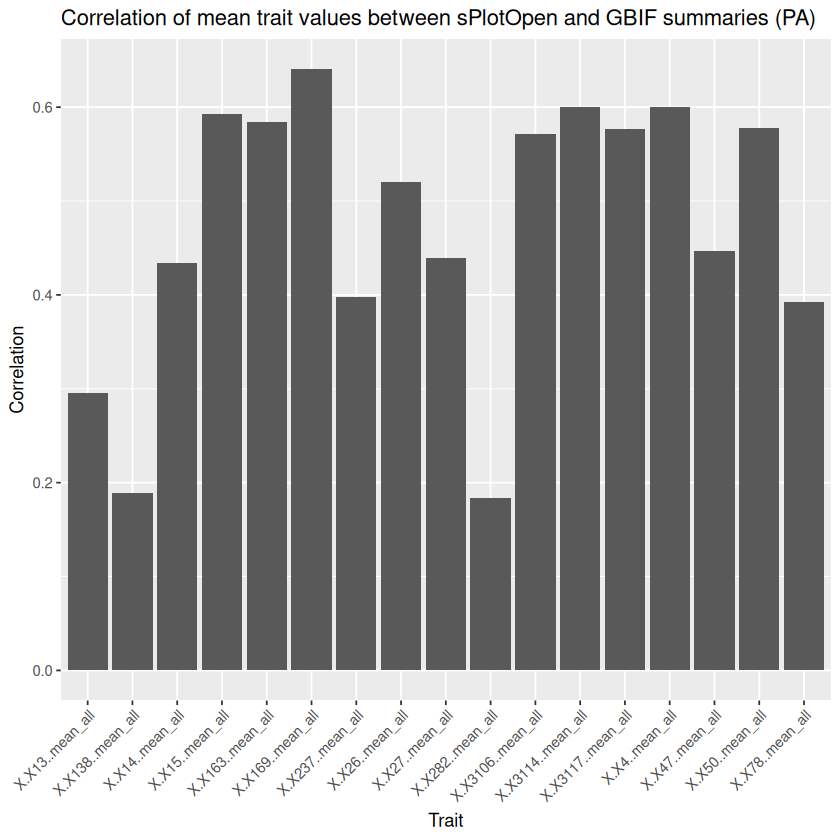

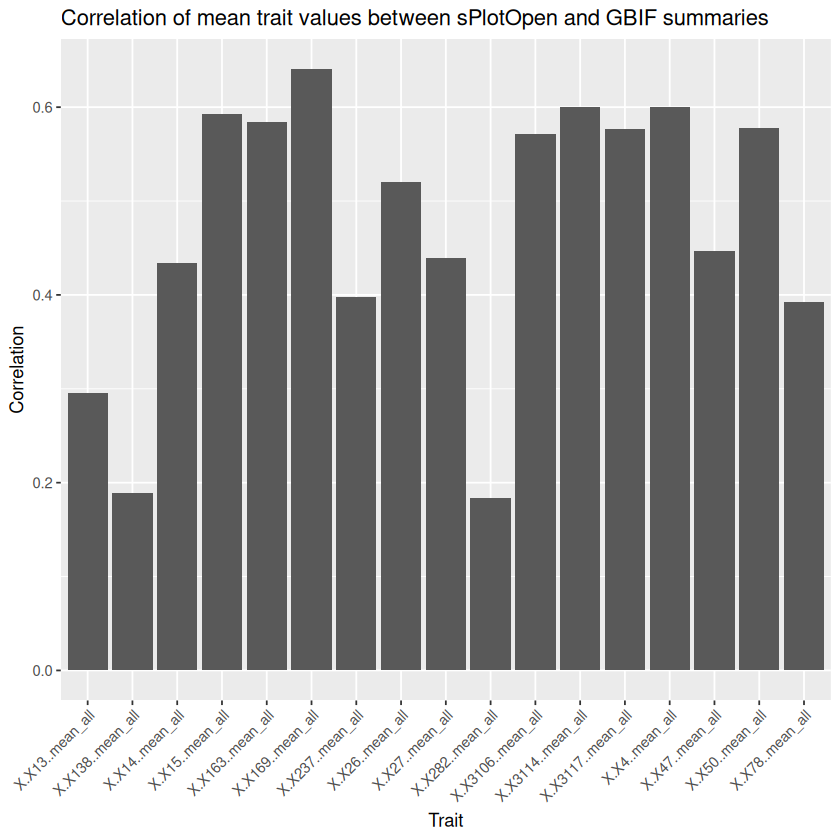

In [41]:
# plot correlation results for presence-absence based summary (cor_results_pa)
library(ggplot2)

cor_df_long <- data.frame(
    Trait = names(cor_results_pa),
    Correlation = cor_results_pa
)

ggplot(cor_df_long, aes(x = Trait, y = Correlation)) +
    geom_bar(stat = "identity") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "Correlation of mean trait values between sPlotOpen and GBIF summaries (PA)")


library(ggplot2)
cor_df_long <- data.frame(
    Trait = names(cor_results_pa),
    Correlation = cor_results_pa
)
ggplot(cor_df_long, aes(x = Trait, y = Correlation)) +
    geom_bar(stat = "identity") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "Correlation of mean trait values between sPlotOpen and GBIF summaries")

    

In [78]:
# compare cor_results_pa and cor_results
cor_comparison <- data.frame(
    Trait = names(cor_results_pa),
    Correlation_PA = cor_results_pa,
    Correlation_Abundance = cor_results,
    Correlation_Notrim = cor_results_notrim,
    Correlation_Notrim_LCweighted = cor_results_notrim_lcweighted
)
cor_comparison

,Trait,Correlation_PA,Correlation_Abundance,Correlation_Notrim,Correlation_Notrim_LCweighted
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
X.X3114..mean_all,X.X3114..mean_all,0.5996580,0.6131830,0.6073129,0.6055280
X.X4..mean_all,X.X4..mean_all,0.6005388,0.5861001,0.5791251,0.5750998
X.X3117..mean_all,X.X3117..mean_all,0.5767928,0.6047750,0.5846386,0.5529832
X.X13..mean_all,X.X13..mean_all,0.2956568,0.3201122,0.3161880,0.3013480
X.X14..mean_all,X.X14..mean_all,0.4338683,0.4728991,0.4577845,0.4270459
X.X15..mean_all,X.X15..mean_all,0.5923461,0.6001907,0.5869732,0.5726631
X.X3106..mean_all,X.X3106..mean_all,0.5713987,0.5821344,0.5817319,0.5866769
X.X26..mean_all,X.X26..mean_all,0.5199775,0.5409606,0.5235787,0.5309473
X.X27..mean_all,X.X27..mean_all,0.4394019,0.4551811,0.4510630,0.4570122


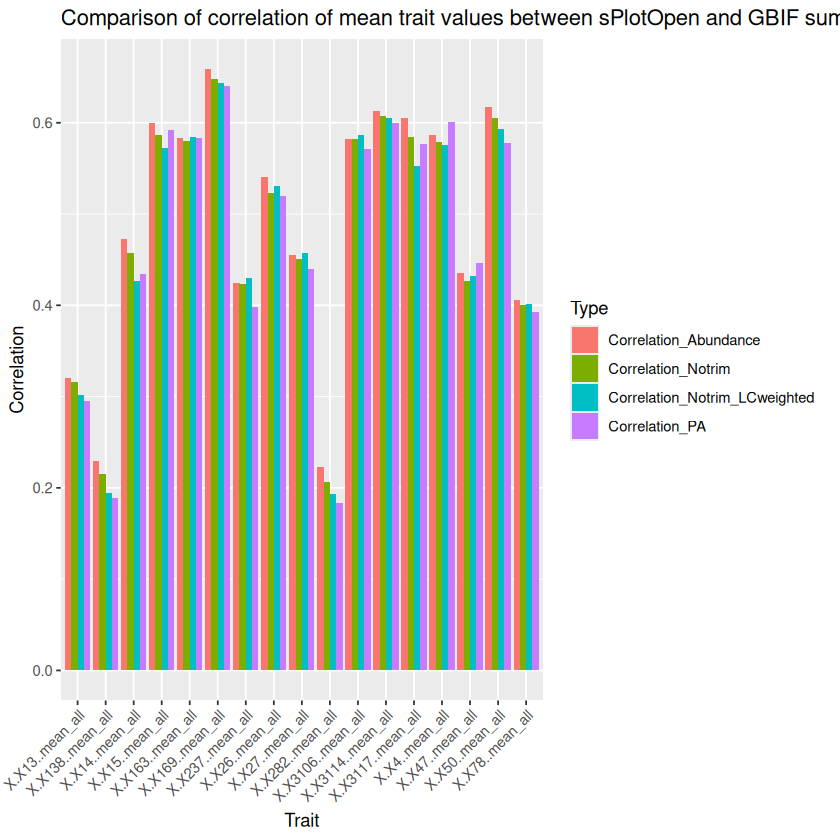

In [79]:
library(tidyr)
# plot cor_comparison including Correlation_Notrim
cor_comparison_long <- cor_comparison %>%
  pivot_longer(cols = c("Correlation_PA", "Correlation_Abundance", "Correlation_Notrim", "Correlation_Notrim_LCweighted"),
               names_to = "Type", values_to = "Correlation")

ggplot(cor_comparison_long, aes(x = Trait, y = Correlation, fill = Type)) +
    geom_bar(stat = "identity", position = "dodge") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "Comparison of correlation of mean trait values between sPlotOpen and GBIF summaries (PA vs Abundance vs Notrim vs Notrim_LCweighted)")

# save figure
ggsave("../Results/Figures/cor_comparison_abund_pa_notrim_lcweighted.png", width = 14, height = 6)
    

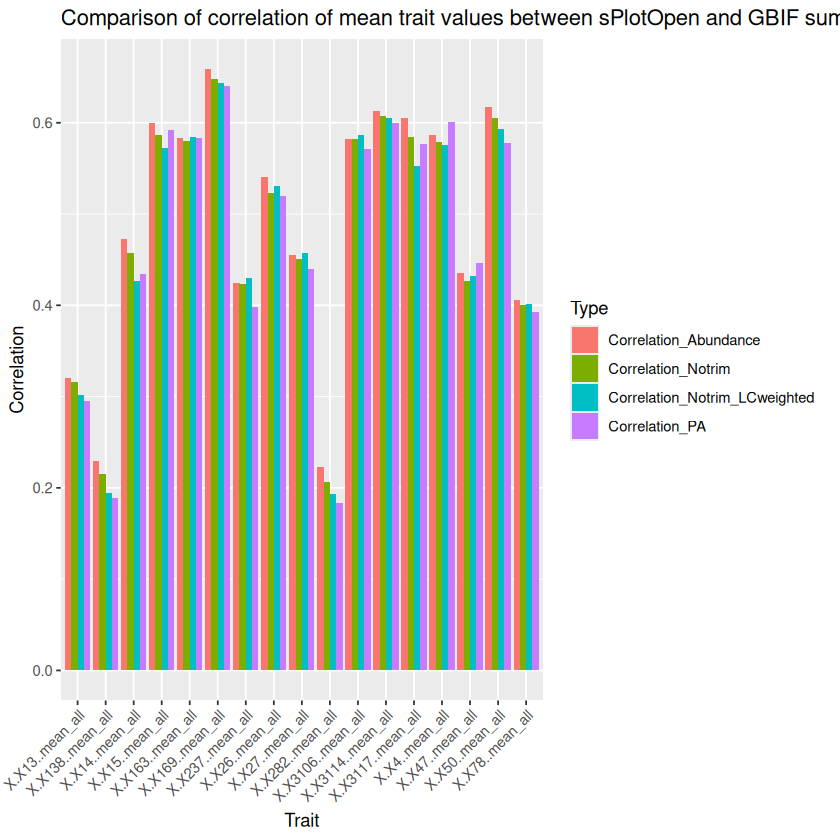

In [107]:
library(tidyr)
# plot cor_comparison including Correlation_Notrim
cor_comparison_long <- cor_comparison %>%
  pivot_longer(cols = c("Correlation_PA", "Correlation_Abundance", "Correlation_Notrim", "Correlation_Notrim_LCweighted"),
               names_to = "Type", values_to = "Correlation")

ggplot(cor_comparison_long, aes(x = Trait, y = Correlation, fill = Type)) +
    geom_bar(stat = "identity", position = "dodge") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "Comparison of correlation of mean trait values between sPlotOpen and GBIF summaries (PA vs Abundance vs Notrim)")

# save figure
ggsave("../Results/Figures/cor_comparison_abund_pa_notrim_LCweighted.png", width = 14, height = 6)
    

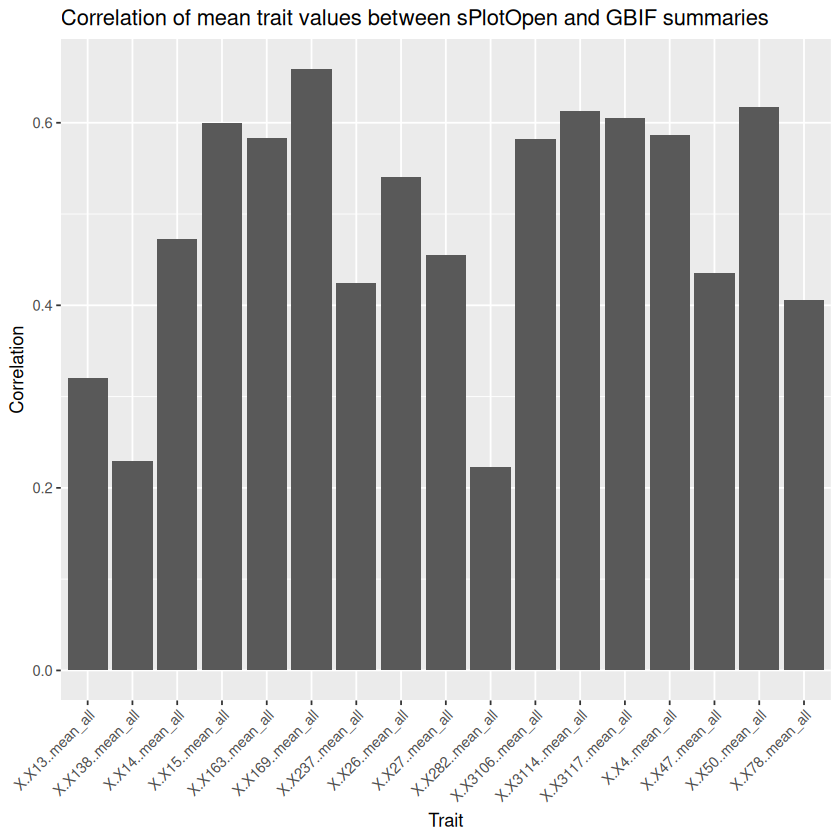

In [29]:
# plot correlation results
library(ggplot2)
cor_df_long <- data.frame(
    Trait = names(cor_results),
    Correlation = cor_results
)
ggplot(cor_df_long, aes(x = Trait, y = Correlation)) +
    geom_bar(stat = "identity") +
    theme(axis.text.x = element_text(angle = 45, hjust = 1)) +
    labs(title = "Correlation of mean trait values between sPlotOpen and GBIF summaries")

    

3. Pick (a subset of) traits where the community science-based maps best reflect vegetation plot CWM'S (no right or wrong way, but justify your choice)

## Calculate PCA

Calculate a Principal Component Analysis for traits selected above

### Variance explained

### Biplot with loadings

### Global maps

Try to interpret PCs in ecological terms using biplots and global maps

## Optional: Regional shifts

Quantify and visualize shifts in trait space in a biome of interest

| Biome Number | Biome Name |
|---------------|-------------|
| 1  | Tropical & Subtropical Moist Broadleaf Forests |
| 2  | Tropical & Subtropical Dry Broadleaf Forests |
| 3  | Tropical & Subtropical Coniferous Forests |
| 4  | Temperate Broadleaf & Mixed Forests |
| 5  | Temperate Conifer Forests |
| 6  | Boreal Forests / Taiga |
| 7  | Tropical & Subtropical Grasslands, Savannas & Shrublands |
| 8  | Temperate Grasslands, Savannas & Shrublands |
| 9  | Flooded Grasslands & Savannas |
| 10 | Montane Grasslands & Shrublands |
| 11 | Tundra |
| 12 | Mediterranean Forests, Woodlands & Scrub |
| 13 | Deserts & Xeric Shrublands |
| 14 | Mangroves |


In [27]:
library(h3)
library(dplyr)
library(sf) 

wwf <- st_read("~/iNaturalist/Data/WWF/wwf_terr_ecos.shp")
print(wwf)

Linking to GEOS 3.12.1, GDAL 3.8.4, PROJ 9.4.0; sf_use_s2() is TRUE



Reading layer `wwf_terr_ecos' from data source 
  `/net/home/swolf/iNaturalist/Data/WWF/wwf_terr_ecos.shp' using driver `ESRI Shapefile'
Simple feature collection with 14458 features and 21 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -89.89197 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
Simple feature collection with 14458 features and 21 fields
Geometry type: POLYGON
Dimension:     XY
Bounding box:  xmin: -180 ymin: -89.89197 xmax: 180 ymax: 83.62313
Geodetic CRS:  WGS 84
First 10 features:
   OBJECTID         AREA PERIMETER                                ECO_NAME
1         1    29.802942     0.219 Northern Mesoamerican Pacific mangroves
2         2    11.977824     0.193 Northern Mesoamerican Pacific mangroves
3         3 77301.372760   111.954                    Sinaloan dry forests
4         4   215.489182     1.274 Northern Mesoamerican Pacific mangroves
5         5    19.639089     0.363 Northern Mesoamerican Pacific mangroves
6         6 19

In [ ]:
# Define biomes of interest
biomes <- 1:14

# Store results for each biome
biome_results <- list()

# Loop through each biome
for (biome_of_interest in biomes) {
    polygon <- wwf[wwf$BIOME == biome_of_interest, ]
    
    if (nrow(polygon) == 0) {
        message(paste("No data for biome", biome_of_interest))
        next
    }
    
    region_cells <- h3::polyfill(polygon, res = 3)
    
    filtered_grid_means <- gbif_summary_pa %>%
        filter(h3_res3 %in% region_cells)
    
    # Store results
    biome_results[[biome_of_interest]] <- filtered_grid_means
}

ERROR: Error: object 'biome_of_interest' not found


## Make Jupyter Book Documentation 

Follow the tutorial here: https://github.com/sojwolf/Jupyter_Workshop_Winterschool_2022?tab=readme-ov-file

or as book: https://sojwolf.github.io/Jupyter_Workshop_Winterschool_2022/intro.html

